# **INTEGRANDES**
*   **Dady Sneider Loaiza Loaiza**
*   **Martín Santiago pinzón Quiceno**



In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy import optimize
from scipy.special import gammaln  # log de la funcion gamma (C2)
import os

C1 = 1106891817 + 1141318622
C2 = 1011099583
S = C1 + C2

In [58]:
pd.set_option("display.width", 140)  # tablas mas anchas al imprimir
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

C1 = 1106891817 + 1141318622  # suma de las dos cedulas del primer bloque
C2 = 1011099583
S = C1 + C2  # semilla y base de todos los parametros

tau = 180 + 10 * (S % 9)  # umbral del SLO en ms
epsilon = 0.01 * (1 + S % 3)  # proporcion maxima tolerada de L > tau
niveles = {0: 0.90, 1: 0.95, 2: 0.99}
confianza = niveles[S % 3]  # nivel 1 - alpha
alpha = 1 - confianza
g = 1.4 + 0.1 * (S % 7)  # factor de crecimiento de la tasa
t1 = 80 + 10 * (S % 5)  # frontera pequena / mediana en KB
t2 = 400 + 25 * (S % 5)  # frontera mediana / grande en KB
pi_prod = (4 + S % 6) / 1000  # prevalencia de incidentes en produccion
k_max = 4 + (S % 5)  # falsas alarmas maximas por dia
r = S % 6  # desplazamiento para B4
N = 10 + (S % 11)  # solicitudes consecutivas para C4

rng = np.random.default_rng(S)

In [59]:
parametros = pd.DataFrame({
    "parametro": ["S", "tau (ms)", "epsilon", "1 - alpha", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N"],
    "valor": [str(S), str(tau), str(round(epsilon, 2)), str(confianza), str(round(g, 1)), str(t1), str(t2),
              str(pi_prod), str(k_max), str(r), str(N)],  # como texto para que no salga en notacion cientifica
})
print(parametros.to_string(index=False))

parametro      valor
        S 3259310022
 tau (ms)        180
  epsilon       0.01
1 - alpha        0.9
        g        1.7
  t1 (KB)        100
  t2 (KB)        450
       pi      0.004
    k_max          6
        r          0
        N         11


# Parte A — Auditoría y preparación de los datos

## A1. Auditoría de `solicitudes.csv`

Revisamos cada columna desde la lógica del sistema: una solicitud con caché no usa GPU, la latencia no puede ser menor que red + GPU (la espera en cola es mayor o igual a cero), los intentos van de 1 a 3 y una solicitud solo puede fallar si agotó los 3 intentos. También buscamos duplicados, nulos, valores negativos y valores fuera de escala. Primero contamos cada problema sobre los datos crudos.

In [60]:
crudos = pd.read_csv("solicitudes.csv")  # datos tal como llegan
print("filas crudas:", len(crudos))
print(crudos.head())
print()
print("nulos por columna:")
print(crudos.isna().sum())

filas crudas: 40951
   id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
0             1       0.0822  308.08          0       A   13.77   49.45        63.22         1      1
1             2       0.1876  827.28          1       B   19.56    0.00        19.56         1      1
2             3       0.2032  608.65          0       B   20.98   23.39        44.37         1      1
3             4       0.2169  278.76          0       A   21.91   30.20        52.10         1      1
4             5       0.2267   84.03          1       A   20.71    0.00        20.71         1      1

nulos por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          41
gpu_ms          40
latencia_ms      0
intentos         0
exito            0
dtype: int64


In [61]:
duplicados_exactos = crudos.duplicated().sum()  # filas identicas en todas las columnas
ids_repetidos = crudos["id_solicitud"].duplicated().sum()  # ids que aparecen mas de una vez
print("filas duplicadas exactas:", duplicados_exactos)
print("ids repetidos:", ids_repetidos)

conteo_ids = crudos["id_solicitud"].value_counts()
ids_con_copia = conteo_ids[conteo_ids > 1].index
ids_de_exactos = set(crudos[crudos.duplicated(keep=False)]["id_solicitud"])
ids_raros = [i for i in ids_con_copia if i not in ids_de_exactos]  # id repetido pero con filas distintas
print("ids repetidos que no son copia exacta:", ids_raros)
print(crudos[crudos["id_solicitud"].isin(ids_raros)])

filas duplicadas exactas: 121
ids repetidos: 122
ids repetidos que no son copia exacta: [21359]
       id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
21416         21359     718.3461  193.45          0       A    12.8     NaN       136.97         1      1
21417         21359     718.3461  193.45          0       A    12.8   14.97       136.97         1      1


In [62]:
print("latencia negativa:", (crudos["latencia_ms"] < 0).sum())
print("valores de latencia negativa:", crudos.loc[crudos["latencia_ms"] < 0, "latencia_ms"].unique())
print("red negativa:", (crudos["red_ms"] < 0).sum())
print("gpu negativa:", (crudos["gpu_ms"] < 0).sum())
print("tam_kb <= 0:", (crudos["tam_kb"] <= 0).sum())
print("gpu > 0 con cache_hit = 1:", ((crudos["gpu_ms"] > 0) & (crudos["cache_hit"] == 1)).sum())
print("gpu = 0 con cache_hit = 0:", ((crudos["gpu_ms"] == 0) & (crudos["cache_hit"] == 0)).sum())
print("intentos fuera de 1..3:", (~crudos["intentos"].isin([1, 2, 3])).sum())
print("tiempos de llegada fuera de [0, 1200]:", ((crudos["t_llegada_s"] < 0) | (crudos["t_llegada_s"] > 1200)).sum())
print("llegadas desordenadas:", (crudos["t_llegada_s"].diff() < 0).sum())
print()
print("tabla intentos vs exito:")
print(pd.crosstab(crudos["intentos"], crudos["exito"]))

latencia negativa: 122
valores de latencia negativa: [-1.]
red negativa: 0
gpu negativa: 0
tam_kb <= 0: 0
gpu > 0 con cache_hit = 1: 0
gpu = 0 con cache_hit = 0: 0
intentos fuera de 1..3: 0
tiempos de llegada fuera de [0, 1200]: 0
llegadas desordenadas: 0

tabla intentos vs exito:
exito       0      1
intentos            
1           0  34209
2           0   5491
3         242   1009


In [63]:
tamanos_ordenados = np.sort(crudos["tam_kb"].values)
print("los 70 tamanos mas grandes:")
print(tamanos_ordenados[-70:].round(1))  # se ve el salto entre ~1600 y ~17000

limite_tam = 5000  # hay un hueco enorme entre ~1600 y ~17000 KB
grandes = crudos[crudos["tam_kb"] > limite_tam]
print("filas con tam_kb > 5000:", len(grandes))
print("mayor tamano normal:", crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].max())
print("menor tamano anomalo:", grandes["tam_kb"].min())
print()
print("cuantiles de los anomalos divididos por 1024:")
print((grandes["tam_kb"] / 1024).quantile([0, 0.25, 0.5, 0.75, 1]).round(1))
print("cuantiles de los tamanos normales:")
print(crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].quantile([0, 0.25, 0.5, 0.75, 1]).round(1))
prueba_ks = stats.ks_2samp(grandes["tam_kb"] / 1024, crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"])
print("KS entre anomalos/1024 y normales: estadistico =", round(prueba_ks.statistic, 3), " p =", round(prueba_ks.pvalue, 3))

los 70 tamanos mas grandes:
[   1269.2    1277.4    1281.5    1288.4    1296.6    1317.8    1351.6
    1396.2    1566.8   17162.2   18606.1   18821.1   40038.4   46489.6
   50288.6   62648.3   85043.2   91658.2   97361.9  121630.7  124129.3
  130252.8  130273.3  131532.8  137502.7  139786.2  141148.2  147425.3
  148377.6  149575.7  151081.   156723.2  156835.8  160983.   161085.4
  161116.2  170690.6  173649.9  175226.9  175851.5  177950.7  203192.3
  213749.8  218204.2  220303.4  226795.5  231977.   239493.1  247275.5
  258897.9  266025.   271953.9  280811.5  282593.3  289003.5  292628.5
  299182.1  315637.8  317829.1  320327.7  374681.6  376350.7  411545.6
  481976.3  498452.5  508825.6  510699.5  679936.   719155.2 1015705.6]
filas con tam_kb > 5000: 61
mayor tamano normal: 1566.78
menor tamano anomalo: 17162.24

cuantiles de los anomalos divididos por 1024:
0.00     16.8
0.25    134.3
0.50    171.7
0.75    282.2
1.00    991.9
Name: tam_kb, dtype: float64
cuantiles de los tamanos no

Los 61 tamaños gigantes, divididos por 1024, caen en el mismo rango que los tamaños normales y la prueba KS no distingue las dos distribuciones. La explicación física más simple es que esas filas se registraron en bytes en lugar de KB, así que los corregimos dividiendo por 1024 en vez de borrarlos.

Ahora revisamos la ecuación de latencia: L = red + espera + G, con espera mayor o igual a 0. Como los datos están redondeados a 0,01 ms, usamos una tolerancia de 0,02 ms.

In [64]:
tolerancia = 0.02  # ms, por el redondeo a dos decimales
residuo = crudos["latencia_ms"] - crudos["red_ms"] - crudos["gpu_ms"]  # esto deberia ser la espera en cola
latencia_valida = crudos["latencia_ms"] > 0
imposibles = latencia_valida & (residuo < -tolerancia)
print("filas con latencia < red + gpu (fuera de tolerancia):", imposibles.sum())
print("de esas, con cache_hit = 1:", (imposibles & (crudos["cache_hit"] == 1)).sum())
print("faltante de latencia en esas filas (ms):")
print(residuo[imposibles].describe().round(2))
print("filas con residuo entre -0.02 y 0 (solo redondeo):", (latencia_valida & (residuo < 0) & (residuo >= -tolerancia)).sum())

filas con latencia < red + gpu (fuera de tolerancia): 80
de esas, con cache_hit = 1: 28
faltante de latencia en esas filas (ms):
count     80.00
mean     -19.80
std       19.45
min     -134.98
25%      -21.85
50%      -14.50
75%       -9.70
max       -3.58
dtype: float64
filas con residuo entre -0.02 y 0 (solo redondeo): 4796


In [65]:
print("nulos de gpu_ms segun cache_hit:")
print(pd.crosstab(crudos["gpu_ms"].isna(), crudos["cache_hit"]))
print("nulos de red_ms segun cache_hit:")
print(pd.crosstab(crudos["red_ms"].isna(), crudos["cache_hit"]))
print("latencia = -1 segun exito:")
print(pd.crosstab(crudos["latencia_ms"] < 0, crudos["exito"]))

nulos de gpu_ms segun cache_hit:
cache_hit      0      1
gpu_ms                 
False      25951  14960
True          24     16
nulos de red_ms segun cache_hit:
cache_hit      0      1
red_ms                 
False      25946  14964
True          29     12
latencia = -1 segun exito:
exito          0      1
latencia_ms            
False        242  40587
True           0    122


Con lo encontrado aplicamos los tratamientos. La regla general es: **no borrar una solicitud que sí ocurrió**, porque las llegadas, los intentos y la caché siguen siendo información válida aunque otra columna esté mal. Solo se borran las copias (filas que no son solicitudes nuevas). Cuando un valor es imposible y no sabemos cuál de las columnas está mal, se marca como faltante (NaN) solo esa columna.

In [66]:
datos = crudos.copy()
filas_iniciales = len(datos)

datos = datos.drop_duplicates()  # 1. quitar copias exactas
quitadas_exactas = filas_iniciales - len(datos)

fila_incompleta = datos["id_solicitud"].isin(ids_raros) & datos["gpu_ms"].isna()  # 2. copia del id repetido sin gpu
datos = datos[~fila_incompleta]
quitadas_id = fila_incompleta.sum()

centinela = datos["latencia_ms"] < 0  # 3. latencia = -1 es un codigo de "no medido"
datos.loc[centinela, "latencia_ms"] = np.nan

en_bytes = datos["tam_kb"] > limite_tam  # 4. tamanos registrados en bytes
datos.loc[en_bytes, "tam_kb"] = datos.loc[en_bytes, "tam_kb"] / 1024

gpu_nula_cache = datos["gpu_ms"].isna() & (datos["cache_hit"] == 1)  # 5. con cache la gpu es 0 por definicion
datos.loc[gpu_nula_cache, "gpu_ms"] = 0.0
gpu_nula_sin_cache = datos["gpu_ms"].isna()  # 6. sin cache no se puede saber la gpu: se deja NaN
red_nula = datos["red_ms"].isna()  # 7. red faltante: se deja NaN

residuo = datos["latencia_ms"] - datos["red_ms"] - datos["gpu_ms"]
latencia_imposible = residuo < -tolerancia  # 8. latencia menor que red + gpu
datos.loc[latencia_imposible, "latencia_ms"] = np.nan

datos = datos.reset_index(drop=True)
print("filas finales:", len(datos))

filas finales: 40829


In [67]:
tabla_a1 = pd.DataFrame({
    "filas afectadas": [
        quitadas_exactas, quitadas_id, centinela.sum(), en_bytes.sum(),
        gpu_nula_cache.sum(), gpu_nula_sin_cache.sum(), red_nula.sum(), latencia_imposible.sum(), 0, 0, 0,
    ],
    "criterio": [
        "fila identica a otra en todas las columnas",
        "id repetido; una copia tiene gpu_ms nulo y la otra completa",
        "latencia_ms = -1 (codigo de 'no medido', no es un tiempo)",
        "tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)",
        "gpu_ms nulo con cache_hit = 1",
        "gpu_ms nulo con cache_hit = 0",
        "red_ms nulo",
        "latencia < red + gpu - 0.02 ms (espera en cola negativa)",
        "gpu_ms > 0 con cache_hit = 1, o gpu_ms = 0 sin cache",
        "intentos fuera de 1..3, o exito = 0 con menos de 3 intentos",
        "tiempos negativos o llegadas fuera de [0, 1200] s",
    ],
    "tratamiento": [
        "eliminar la copia",
        "conservar la fila completa",
        "latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu",
        "dividir tam_kb entre 1024 (estaba en bytes)",
        "imputar gpu_ms = 0 (por definicion del sistema)",
        "dejar NaN; se excluye solo en analisis de gpu",
        "dejar NaN; se excluye solo en analisis de red",
        "latencia -> NaN (no se sabe que columna fallo)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
    ],
})
print(tabla_a1.to_string(index=False))
print()
print("filas crudas:", filas_iniciales, " -> filas limpias:", len(datos))
print("latencias disponibles:", datos["latencia_ms"].notna().sum())

 filas afectadas                                                                                criterio                                                             tratamiento
             121                                              fila identica a otra en todas las columnas                                                       eliminar la copia
               1                             id repetido; una copia tiene gpu_ms nulo y la otra completa                                              conservar la fila completa
             122                               latencia_ms = -1 (codigo de 'no medido', no es un tiempo) latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu
              61 tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)                             dividir tam_kb entre 1024 (estaba en bytes)
              16                                                           gpu_ms nulo con cache_hit = 1           

**Conclusión A1.** Solo se eliminan las copias (122 filas), porque no son solicitudes nuevas e inflarían la tasa de llegadas. El resto de problemas se corrige (tamaños en bytes, GPU nula con caché) o se marca como faltante solo en la columna afectada. Las comprobaciones de coherencia entre caché y GPU, intentos y éxito, y tiempos de llegada no encontraron problemas.

## A2. ¿Un solo régimen en toda la ventana?

Si toda la ventana fuera un único proceso de Poisson, los conteos por intervalo tendrían varianza igual a la media (índice de dispersión 1). Lo probamos con la prueba de dispersión (chi-cuadrado). Después buscamos el segmento anómalo con un barrido de punto de cambio: probamos todos los pares (inicio, fin) y nos quedamos con el que maximiza la log-verosimilitud de un modelo con una tasa adentro y otra afuera.

In [68]:
ancho = 10  # segundos por intervalo
bordes = np.arange(0, 1200 + ancho, ancho)
conteos, _ = np.histogram(datos["t_llegada_s"], bins=bordes)  # llegadas por intervalo de 10 s

media_conteos = conteos.mean()
var_conteos = conteos.var(ddof=1)
indice_dispersion = var_conteos / media_conteos
estadistico_disp = (len(conteos) - 1) * indice_dispersion  # chi-cuadrado con k-1 grados de libertad
p_disp = stats.chi2.sf(estadistico_disp, df=len(conteos) - 1)
print("media de conteos por 10 s:", round(media_conteos, 1))
print("varianza:", round(var_conteos, 1))
print("indice de dispersion:", round(indice_dispersion, 2))
print("p-valor prueba de dispersion:", p_disp)

media de conteos por 10 s: 340.2
varianza: 19261.9
indice de dispersion: 56.61
p-valor prueba de dispersion: 0.0


El índice de dispersión es muy mayor que 1 y el p-valor es prácticamente 0, así que la ventana completa **no** es un solo proceso de Poisson. Ahora buscamos dónde está el cambio. Para un modelo de Poisson, la log-verosimilitud de un segmento con total T y m intervalos es T·log(T/m) − T (más una constante que no depende del corte). Para los reintentos usamos el mismo barrido con un modelo binomial.

In [69]:
def barrido_segmento(exitos, totales, modelo):
    # busca el par (i, j) que separa los intervalos i..j-1 del resto
    m = len(exitos)
    mejor = (-np.inf, 0, 0)
    for i in range(1, m):
        for j in range(i + 1, m + 1):
            dentro_e = exitos[i:j].sum()
            fuera_e = exitos.sum() - dentro_e
            dentro_n = totales[i:j].sum()
            fuera_n = totales.sum() - dentro_n
            if modelo == "poisson":
                ll = dentro_e * np.log(dentro_e / dentro_n) - dentro_e + fuera_e * np.log(fuera_e / fuera_n) - fuera_e
            else:
                p1 = dentro_e / dentro_n
                p2 = fuera_e / fuera_n
                ll = dentro_e * np.log(p1) + (dentro_n - dentro_e) * np.log(1 - p1) + fuera_e * np.log(p2) + (fuera_n - fuera_e) * np.log(1 - p2)
            if ll > mejor[0]:
                mejor = (ll, i, j)
    return mejor


def log_ver_un_regimen(exitos, totales, modelo):
    tot_e = exitos.sum()
    tot_n = totales.sum()
    if modelo == "poisson":
        return tot_e * np.log(tot_e / tot_n) - tot_e
    p = tot_e / tot_n
    return tot_e * np.log(p) + (tot_n - tot_e) * np.log(1 - p)

In [70]:
resultados_a2 = []
for ancho_prueba in [5, 10, 20]:
    bordes_prueba = np.arange(0, 1200 + ancho_prueba, ancho_prueba)
    llegadas, _ = np.histogram(datos["t_llegada_s"], bins=bordes_prueba)
    reintentos, _ = np.histogram(datos.loc[datos["intentos"] > 1, "t_llegada_s"], bins=bordes_prueba)

    ll, i, j = barrido_segmento(llegadas, np.ones(len(llegadas)), "poisson")  # tasa de llegadas
    razon = 2 * (ll - log_ver_un_regimen(llegadas, np.ones(len(llegadas)), "poisson"))
    resultados_a2.append(["llegadas (Poisson)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])

    ll, i, j = barrido_segmento(reintentos, llegadas, "binomial")  # proporcion de reintentos
    razon = 2 * (ll - log_ver_un_regimen(reintentos, llegadas, "binomial"))
    resultados_a2.append(["reintentos (binomial)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])

tabla_a2 = pd.DataFrame(resultados_a2, columns=["criterio", "ancho (s)", "inicio (s)", "fin (s)", "razon de verosimilitud", "p-valor aprox"])
print(tabla_a2.to_string(index=False))

             criterio  ancho (s)  inicio (s)  fin (s)  razon de verosimilitud  p-valor aprox
   llegadas (Poisson)          5         695      860             5397.291103   0.000000e+00
reintentos (binomial)          5         695      860              927.176011  1.127915e-200
   llegadas (Poisson)         10         690      860             5262.152312   0.000000e+00
reintentos (binomial)         10         690      860              917.056836  1.767051e-198
   llegadas (Poisson)         20         700      860             5232.359596   0.000000e+00
reintentos (binomial)         20         680      860              900.351306  7.427210e-195


La razón de verosimilitud compara "dos regímenes" contra "uno". Como los puntos de corte se eligen buscando el máximo, el p-valor chi-cuadrado (3 grados de libertad: dos cortes y una tasa extra) es solo aproximado, pero la razón es tan grande que la conclusión no cambia. Los seis criterios ubican el segmento anómalo prácticamente en el mismo lugar (entre ~690 y ~860 s), lo que muestra que la conclusión es poco sensible al ancho del intervalo y a la variable usada. Fijamos el criterio principal: llegadas con intervalos de 10 s.

In [71]:
fila_principal = tabla_a2[(tabla_a2["criterio"] == "llegadas (Poisson)") & (tabla_a2["ancho (s)"] == 10)]
inicio_anomalo = float(fila_principal["inicio (s)"].iloc[0])
fin_anomalo = float(fila_principal["fin (s)"].iloc[0])
print("segmento anomalo: [", inicio_anomalo, ",", fin_anomalo, ") s")

datos["regimen"] = "estable"
en_anomalo = (datos["t_llegada_s"] >= inicio_anomalo) & (datos["t_llegada_s"] < fin_anomalo)
datos.loc[en_anomalo, "regimen"] = "anomalo"
duracion_anomalo = fin_anomalo - inicio_anomalo
duracion_estable = 1200 - duracion_anomalo

resumen_regimen = datos.groupby("regimen").agg(
    solicitudes=("id_solicitud", "size"),
    prop_reintentos=("intentos", lambda x: (x > 1).mean()),
    prop_cache=("cache_hit", "mean"),
    latencia_media=("latencia_ms", "mean"),
)
resumen_regimen["duracion (s)"] = [duracion_anomalo, duracion_estable]
resumen_regimen["tasa (sol/s)"] = resumen_regimen["solicitudes"] / resumen_regimen["duracion (s)"]
print(resumen_regimen.round(3))

segmento anomalo: [ 690.0 , 860.0 ) s
         solicitudes  prop_reintentos  prop_cache  latencia_media  duracion (s)  tasa (sol/s)
regimen                                                                                      
anomalo        11442            0.257       0.372         119.259         170.0        67.306
estable        29387            0.129       0.363          48.413        1030.0        28.531


Falta comprobar que el tramo antes del segmento anómalo y el tramo después son **el mismo** régimen (si no, no podríamos juntarlos). Condicionado al total, el número de llegadas en el primer tramo es binomial con p = duración1 / (duración1 + duración2) si las tasas son iguales. Hacemos lo mismo con la proporción de reintentos (prueba chi-cuadrado de una tabla 2x2).

In [72]:
antes = datos[datos["t_llegada_s"] < inicio_anomalo]
despues = datos[datos["t_llegada_s"] >= fin_anomalo]
duracion_antes = inicio_anomalo
duracion_despues = 1200 - fin_anomalo

prueba_tasas = stats.binomtest(len(antes), len(antes) + len(despues), duracion_antes / (duracion_antes + duracion_despues))
print("tasa antes:", round(len(antes) / duracion_antes, 2), "sol/s  | tasa despues:", round(len(despues) / duracion_despues, 2), "sol/s")
print("p-valor igualdad de tasas:", round(prueba_tasas.pvalue, 3))

tabla_reint = [[(antes["intentos"] > 1).sum(), (antes["intentos"] == 1).sum()],
               [(despues["intentos"] > 1).sum(), (despues["intentos"] == 1).sum()]]
chi2_reint, p_reint, _, _ = stats.chi2_contingency(tabla_reint)
print("reintentos antes:", round((antes["intentos"] > 1).mean(), 4), " despues:", round((despues["intentos"] > 1).mean(), 4))
print("p-valor igualdad de reintentos:", round(p_reint, 3))

conteos_estable, _ = np.histogram(datos.loc[datos["regimen"] == "estable", "t_llegada_s"], bins=bordes)
conteos_estable = conteos_estable[(bordes[:-1] < inicio_anomalo) | (bordes[:-1] >= fin_anomalo)]  # solo intervalos del regimen estable
indice_estable = conteos_estable.var(ddof=1) / conteos_estable.mean()
p_disp_estable = 2 * min(stats.chi2.sf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1),
                         stats.chi2.cdf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1))
print("indice de dispersion dentro del regimen estable:", round(indice_estable, 3), " p-valor (dos colas):", round(p_disp_estable, 3))

tasa antes: 28.5 sol/s  | tasa despues: 28.59 sol/s
p-valor igualdad de tasas: 0.818
reintentos antes: 0.128  despues: 0.1304
p-valor igualdad de reintentos: 0.578
indice de dispersion dentro del regimen estable: 0.932  p-valor (dos colas): 0.653


In [73]:
sensibilidad = []
for _, fila in tabla_a2.iterrows():
    fuera = (datos["t_llegada_s"] < fila["inicio (s)"]) | (datos["t_llegada_s"] >= fila["fin (s)"])
    dur = 1200 - (fila["fin (s)"] - fila["inicio (s)"])
    sensibilidad.append([fila["criterio"], fila["ancho (s)"], fila["inicio (s)"], fila["fin (s)"],
                         fuera.sum(), fuera.sum() / dur, (datos.loc[fuera, "intentos"] > 1).mean()])
tabla_sens = pd.DataFrame(sensibilidad, columns=["criterio", "ancho (s)", "inicio", "fin", "n estable", "tasa estable (sol/s)", "prop reintentos estable"])
print(tabla_sens.round(4).to_string(index=False))

             criterio  ancho (s)  inicio  fin  n estable  tasa estable (sol/s)  prop reintentos estable
   llegadas (Poisson)          5     695  860      29536               28.5372                   0.1289
reintentos (binomial)          5     695  860      29536               28.5372                   0.1289
   llegadas (Poisson)         10     690  860      29387               28.5311                   0.1288
reintentos (binomial)         10     690  860      29387               28.5311                   0.1288
   llegadas (Poisson)         20     700  860      29859               28.7106                   0.1302
reintentos (binomial)         20     680  860      29098               28.5275                   0.1285


**Conclusión A2.** La ventana no puede modelarse con un único régimen: la prueba de dispersión y la razón de verosimilitud rechazan un solo régimen con p-valor prácticamente 0. Hay un segmento anómalo, aproximadamente entre 690 y 860 s, donde la tasa de llegadas se multiplica por más de 2 y la proporción de reintentos casi se duplica. Los tramos antes y después de ese segmento no muestran diferencias significativas en tasa ni en reintentos, y dentro de ellos los conteos se comportan como Poisson (índice de dispersión cercano a 1). Por eso el **régimen estable** de las partes B a F es la unión de [0, 690) s y [860, 1200] s. La tabla de sensibilidad muestra que, con cualquiera de los seis criterios, la tasa y la proporción de reintentos del régimen estable cambian solo en el tercer o cuarto decimal.

## A3. Resumen descriptivo por versión y por régimen

Calculamos centro (media y mediana), dispersión (desviación estándar y rango intercuartílico), asimetría y curtosis en exceso (0 para la normal) de las cuatro variables. Para `gpu_ms` usamos solo las solicitudes sin caché, porque con caché vale 0 por definición y mezclar ambas cosas distorsiona el resumen (en C1 se trata la variable mixta completa).

In [74]:
def resumen(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(serie),
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_est": serie.std(),
        "RIC": q3 - q1,
        "asimetria": stats.skew(serie),
        "curtosis_exc": stats.kurtosis(serie),
    })


variables = {"latencia_ms": datos, "gpu_ms (sin cache)": datos[datos["cache_hit"] == 0],
             "red_ms": datos, "tam_kb": datos}
tablas_a3 = []
for nombre, tabla in variables.items():
    columna = nombre.split(" ")[0]
    for (regimen, version), grupo in tabla.groupby(["regimen", "version"]):
        fila = resumen(grupo[columna])
        fila["variable"] = nombre
        fila["regimen"] = regimen
        fila["version"] = version
        tablas_a3.append(fila)
tabla_a3 = pd.DataFrame(tablas_a3)[["variable", "regimen", "version", "n", "media", "mediana", "desv_est", "RIC", "asimetria", "curtosis_exc"]]
print(tabla_a3.round(2).to_string(index=False))

          variable regimen version       n  media  mediana  desv_est    RIC  asimetria  curtosis_exc
       latencia_ms anomalo       A  5652.0 119.17    64.48    142.42 136.37       2.06          4.45
       latencia_ms anomalo       B  5731.0 119.35    61.73    144.30 137.38       2.07          4.39
       latencia_ms estable       A 14633.0  50.17    40.17     37.63  46.25       1.88          5.51
       latencia_ms estable       B 14610.0  46.65    37.00     34.43  41.13       1.88          5.16
gpu_ms (sin cache) anomalo       A  3546.0  42.44    34.06     33.36  34.72       2.47         11.21
gpu_ms (sin cache) anomalo       B  3633.0  38.44    30.09     29.37  30.69       2.10          7.20
gpu_ms (sin cache) estable       A  9464.0  43.07    34.22     33.57  35.35       2.17          7.65
gpu_ms (sin cache) estable       B  9238.0  38.42    30.70     29.68  31.16       2.08          6.93
            red_ms anomalo       A  5678.0  19.00    19.01      2.80   3.84      -0.00     

**Figura 1.** Evolución temporal del sistema en intervalos de 10 s: tasa de llegadas, proporción de solicitudes con reintento, latencia media y tiempo medio de GPU (sin caché). La franja sombreada es el segmento anómalo detectado en A2.

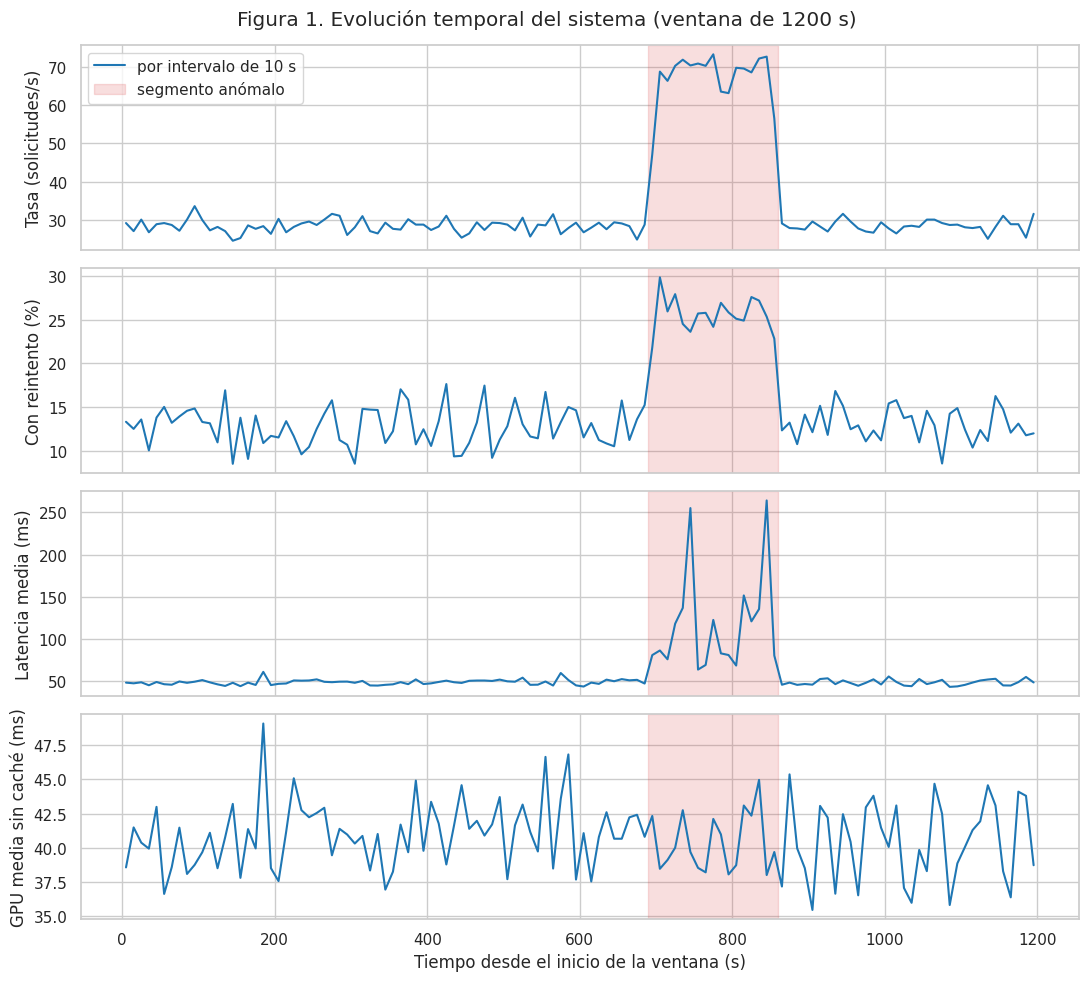

In [75]:
datos["intervalo"] = (datos["t_llegada_s"] // ancho).astype(int)
por_intervalo = datos.groupby("intervalo").agg(
    llegadas=("id_solicitud", "size"),
    reintentos=("intentos", lambda x: (x > 1).mean()),
    latencia=("latencia_ms", "mean"),
)
por_intervalo["gpu"] = datos[datos["cache_hit"] == 0].groupby("intervalo")["gpu_ms"].mean()
tiempo_centro = por_intervalo.index * ancho + ancho / 2  # centro de cada intervalo en s

fig, ejes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
series = [
    (por_intervalo["llegadas"] / ancho, "Tasa (solicitudes/s)"),
    (por_intervalo["reintentos"] * 100, "Con reintento (%)"),
    (por_intervalo["latencia"], "Latencia media (ms)"),
    (por_intervalo["gpu"], "GPU media sin caché (ms)"),
]
for eje, (valores, etiqueta) in zip(ejes, series):
    eje.plot(tiempo_centro, valores, color="tab:blue", label="por intervalo de 10 s")
    eje.axvspan(inicio_anomalo, fin_anomalo, color="tab:red", alpha=0.15, label="segmento anómalo")
    eje.set_ylabel(etiqueta)
ejes[0].legend(loc="upper left")
ejes[-1].set_xlabel("Tiempo desde el inicio de la ventana (s)")
fig.suptitle("Figura 1. Evolución temporal del sistema (ventana de 1200 s)")
plt.tight_layout()
plt.show()

*Pie de Figura 1.* Entre ~690 y ~860 s la tasa de llegadas se dispara, los reintentos casi se duplican y la latencia media sube mucho, pero el tiempo de GPU por solicitud no cambia. El lector debe concluir que el episodio es una ráfaga de tráfico que congestiona la cola, no una GPU más lenta, y que fuera de esa franja el sistema es estable.

**Conclusión A3.** La latencia es la variable que más cambia entre regímenes: en el anómalo su media se duplica con creces y su desviación estándar casi se cuadruplica, por la espera en cola. `gpu_ms`, `red_ms` y `tam_kb` tienen resúmenes casi iguales en ambos regímenes, así que lo que cambia en el episodio anómalo es la carga, no el costo de cada solicitud. `gpu_ms` y `latencia_ms` son muy asimétricas a la derecha y con curtosis alta (colas pesadas); `tam_kb` también es asimétrica, pero menos. `red_ms` es casi simétrica (asimetría y curtosis cercanas a 0), lo que anticipa que podría ser normal (C3). Entre versiones, la B muestra un tiempo medio de GPU unos 4 a 5 ms menor que la A en ambos regímenes, sin diferencias en red ni en tamaño; esto se analiza formalmente en F3.

# Parte B — Llegadas, fallos y reintentos

In [76]:
estable = datos[datos["regimen"] == "estable"].copy()  # regimen estable de A2
anomalo = datos[datos["regimen"] == "anomalo"].copy()
z = stats.norm.ppf(1 - alpha / 2)  # valor critico para intervalos al nivel 1 - alpha
print("solicitudes en regimen estable:", len(estable), " duracion:", duracion_estable, "s")
print("solicitudes en regimen anomalo:", len(anomalo), " duracion:", duracion_anomalo, "s")
print("nivel de confianza:", confianza, " z =", round(z, 4))

solicitudes en regimen estable: 29387  duracion: 1030.0 s
solicitudes en regimen anomalo: 11442  duracion: 170.0 s
nivel de confianza: 0.9  z = 1.6449


## B1. Modelo del proceso de llegadas

Proponemos un **proceso de Poisson homogéneo** con tasa λ: los tiempos entre llegadas son exponenciales independientes con media 1/λ y el número de llegadas en un intervalo de largo h es Poisson(λh). El estimador de máxima verosimilitud de λ observando una ventana de duración T es λ̂ = n / T. El intervalo de confianza exacto sale de la relación entre la Poisson y la chi-cuadrado (intervalo de Garwood).

Los tiempos entre llegadas se calculan **dentro** de cada tramo estable, para no contar el hueco del segmento anómalo como un tiempo entre llegadas.

In [77]:
llegadas_antes = estable.loc[estable["t_llegada_s"] < inicio_anomalo, "t_llegada_s"].values
llegadas_despues = estable.loc[estable["t_llegada_s"] >= fin_anomalo, "t_llegada_s"].values
tiempos_entre_llegadas = np.concatenate([np.diff(llegadas_antes), np.diff(llegadas_despues)])  # en segundos

n_llegadas = len(estable)
lambda_hat = n_llegadas / duracion_estable  # EMV de la tasa (sol/s)
lambda_inf = stats.chi2.ppf(alpha / 2, 2 * n_llegadas) / (2 * duracion_estable)  # Garwood
lambda_sup = stats.chi2.ppf(1 - alpha / 2, 2 * n_llegadas + 2) / (2 * duracion_estable)

print("numero de tiempos entre llegadas:", len(tiempos_entre_llegadas))
print("media de los tiempos entre llegadas:", round(tiempos_entre_llegadas.mean() * 1000, 3), "ms")
print("coeficiente de variacion (exponencial = 1):", round(tiempos_entre_llegadas.std() / tiempos_entre_llegadas.mean(), 4))
print(f"lambda = {lambda_hat:.3f} [{lambda_inf:.3f}, {lambda_sup:.3f}] sol/s, nivel {confianza}, metodo exacto chi-cuadrado (Garwood)")
print(f"media entre llegadas 1/lambda = {1000 / lambda_hat:.3f} [{1000 / lambda_sup:.3f}, {1000 / lambda_inf:.3f}] ms, mismo nivel y metodo (transformado)")

numero de tiempos entre llegadas: 29385
media de los tiempos entre llegadas: 35.038 ms
coeficiente de variacion (exponencial = 1): 1.0052
lambda = 28.531 [28.258, 28.806] sol/s, nivel 0.9, metodo exacto chi-cuadrado (Garwood)
media entre llegadas 1/lambda = 35.050 [34.715, 35.388] ms, mismo nivel y metodo (transformado)


**Validación 1 — tiempos entre llegadas (prueba KS).** Comparamos la distribución empírica de los tiempos entre llegadas con una exponencial de tasa λ̂. Como λ se estimó con los mismos datos, el p-valor de la tabla KS es optimista; por eso calculamos el p-valor por **bootstrap paramétrico**: simulamos muestras exponenciales del mismo tamaño, re-estimamos λ en cada una y vemos qué tan seguido el estadístico KS simulado supera al observado.

In [78]:
ks_observado = stats.kstest(tiempos_entre_llegadas, "expon", args=(0, 1 / lambda_hat)).statistic
print("estadistico KS observado:", round(ks_observado, 5))

replicas_ks = 300  # suficiente para un p-valor con error estandar menor a 0.03
ks_simulados = np.zeros(replicas_ks)
for i in range(replicas_ks):
    muestra = rng.exponential(1 / lambda_hat, size=len(tiempos_entre_llegadas))
    tasa_muestra = 1 / muestra.mean()  # re-estimar como con los datos reales
    ks_simulados[i] = stats.kstest(muestra, "expon", args=(0, 1 / tasa_muestra)).statistic
p_ks_bootstrap = (ks_simulados >= ks_observado).mean()
print("p-valor KS por bootstrap parametrico:", round(p_ks_bootstrap, 3))

estadistico KS observado: 0.00428
p-valor KS por bootstrap parametrico: 0.457


**Validación 2 — conteos por segundo (chi-cuadrado de bondad de ajuste).** Contamos las llegadas en cada segundo del régimen estable (1030 intervalos) y comparamos las frecuencias observadas con las esperadas bajo Poisson(λ̂·1 s). Agrupamos las colas para que cada categoría tenga frecuencia esperada de al menos 5. Los grados de libertad son (categorías − 1 − 1) porque estimamos λ.

In [79]:
segundos_estables = np.r_[np.arange(0, inicio_anomalo), np.arange(fin_anomalo, 1200)]  # inicio de cada segundo estable
conteos_por_segundo = np.zeros(len(segundos_estables), dtype=int)
segundo_de_llegada = np.floor(estable["t_llegada_s"].values).astype(int)
for i, segundo in enumerate(segundos_estables):
    conteos_por_segundo[i] = (segundo_de_llegada == segundo).sum()

media_seg = conteos_por_segundo.mean()
var_seg = conteos_por_segundo.var(ddof=1)
print("media por segundo:", round(media_seg, 3), " varianza:", round(var_seg, 3), " indice de dispersion:", round(var_seg / media_seg, 3))

limite_bajo = int(stats.poisson.ppf(0.01, lambda_hat))  # agrupar cola izquierda
limite_alto = int(stats.poisson.ppf(0.99, lambda_hat))  # agrupar cola derecha
valores = np.arange(limite_bajo, limite_alto + 1)
observadas = []
esperadas = []
for v in valores:
    if v == limite_bajo:
        observadas.append((conteos_por_segundo <= v).sum())
        esperadas.append(stats.poisson.cdf(v, lambda_hat) * len(conteos_por_segundo))
    elif v == limite_alto:
        observadas.append((conteos_por_segundo >= v).sum())
        esperadas.append(stats.poisson.sf(v - 1, lambda_hat) * len(conteos_por_segundo))
    else:
        observadas.append((conteos_por_segundo == v).sum())
        esperadas.append(stats.poisson.pmf(v, lambda_hat) * len(conteos_por_segundo))
observadas = np.array(observadas)
esperadas = np.array(esperadas)
chi2_conteos = ((observadas - esperadas) ** 2 / esperadas).sum()
gl_conteos = len(valores) - 2
p_conteos = stats.chi2.sf(chi2_conteos, gl_conteos)
print("categorias:", len(valores), " menor esperada:", round(esperadas.min(), 1))
print("chi-cuadrado =", round(chi2_conteos, 2), " gl =", gl_conteos, " p-valor =", round(p_conteos, 3))

estadistico_disp_seg = (len(conteos_por_segundo) - 1) * var_seg / media_seg
p_disp_seg = 2 * min(stats.chi2.sf(estadistico_disp_seg, len(conteos_por_segundo) - 1),
                     stats.chi2.cdf(estadistico_disp_seg, len(conteos_por_segundo) - 1))
print("prueba de dispersion por segundo: p-valor (dos colas) =", round(p_disp_seg, 3))

media por segundo: 28.531  varianza: 28.329  indice de dispersion: 0.993
categorias: 26  menor esperada: 5.8
chi-cuadrado = 18.71  gl = 24  p-valor = 0.768
prueba de dispersion por segundo: p-valor (dos colas) = 0.884


**Validación 3 — independencia.** Un proceso de Poisson tiene tiempos entre llegadas independientes. Revisamos la autocorrelación de los tiempos entre llegadas consecutivos en los primeros rezagos; bajo independencia cada una debería estar dentro de ±z/√n.

In [80]:
banda = z / np.sqrt(len(tiempos_entre_llegadas))
for rezago in [1, 2, 3, 5, 10]:
    autocorr = np.corrcoef(tiempos_entre_llegadas[:-rezago], tiempos_entre_llegadas[rezago:])[0, 1]
    print("rezago", rezago, " autocorrelacion =", round(autocorr, 4), " dentro de la banda:", abs(autocorr) < banda)
print("banda: +/-", round(banda, 4))

rezago 1  autocorrelacion = -0.0025  dentro de la banda: True
rezago 2  autocorrelacion = 0.0021  dentro de la banda: True
rezago 3  autocorrelacion = -0.0036  dentro de la banda: True
rezago 5  autocorrelacion = -0.0061  dentro de la banda: True
rezago 10  autocorrelacion = -0.0023  dentro de la banda: True
banda: +/- 0.0096


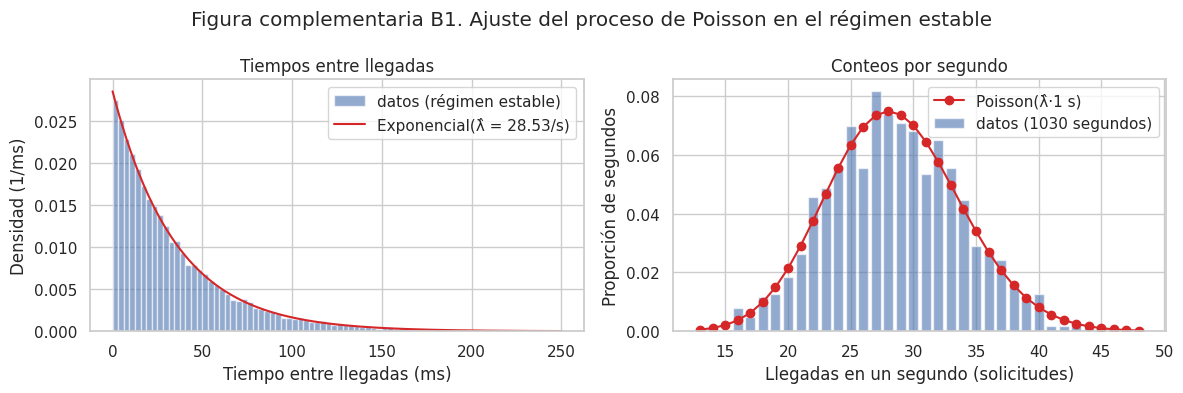

In [81]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
x_ms = np.linspace(0, 250, 300)
ejes[0].hist(tiempos_entre_llegadas * 1000, bins=80, range=(0, 250), density=True, alpha=0.6, label="datos (régimen estable)")
ejes[0].plot(x_ms, lambda_hat / 1000 * np.exp(-lambda_hat * x_ms / 1000), color="tab:red", label=f"Exponencial(λ̂ = {lambda_hat:.2f}/s)")
ejes[0].set_xlabel("Tiempo entre llegadas (ms)")
ejes[0].set_ylabel("Densidad (1/ms)")
ejes[0].set_title("Tiempos entre llegadas")
ejes[0].legend()

valores_k = np.arange(conteos_por_segundo.min(), conteos_por_segundo.max() + 1)
frec_obs = np.array([(conteos_por_segundo == k).mean() for k in valores_k])
ejes[1].bar(valores_k, frec_obs, alpha=0.6, label="datos (1030 segundos)")
ejes[1].plot(valores_k, stats.poisson.pmf(valores_k, lambda_hat), "o-", color="tab:red", label="Poisson(λ̂·1 s)")
ejes[1].set_xlabel("Llegadas en un segundo (solicitudes)")
ejes[1].set_ylabel("Proporción de segundos")
ejes[1].set_title("Conteos por segundo")
ejes[1].legend()
fig.suptitle("Figura complementaria B1. Ajuste del proceso de Poisson en el régimen estable")
plt.tight_layout()
plt.show()

*Pie de figura complementaria B1.* Tanto el histograma de tiempos entre llegadas como la distribución de conteos por segundo siguen de cerca las curvas teóricas. El lector debe concluir que el proceso de Poisson describe bien las llegadas del régimen estable.

**Conclusión B1.** En el régimen estable las llegadas se modelan como un proceso de Poisson. Tres vías cuantitativas distintas no encuentran evidencia contra el modelo: la prueba KS de los tiempos entre llegadas con p-valor por bootstrap, la chi-cuadrado de los conteos por segundo con su prueba de dispersión, y la autocorrelación. El coeficiente de variación de los tiempos entre llegadas es prácticamente 1, como en la exponencial. La tasa estimada y su intervalo aparecen arriba en el formato pedido.

## B2. Solicitudes con más de un intento por bloque de 100

Si cada solicitud necesita más de un intento con la misma probabilidad p, independientemente de las demás, el número de ellas en un bloque de 100 solicitudes consecutivas es **Binomial(100, p)**. Armamos los bloques dentro de cada régimen por separado, estimamos p en cada uno y contrastamos el modelo de tres formas: media y varianza contra las de la binomial, prueba de dispersión y chi-cuadrado de bondad de ajuste.

In [82]:
def conteos_por_bloque(tabla, tamano_bloque):
    con_reintento = (tabla["intentos"].values > 1).astype(int)  # 1 si necesito mas de un intento
    num_bloques = len(con_reintento) // tamano_bloque  # se descarta el bloque incompleto del final
    return con_reintento[:num_bloques * tamano_bloque].reshape(num_bloques, tamano_bloque).sum(axis=1)


def chi2_binomial(conteos, n_ensayos, p):
    # agrupa en ~6 categorias de probabilidad parecida para que las esperadas sean grandes
    cortes = np.unique(stats.binom.ppf([1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6], n_ensayos, p))
    observadas = []
    esperadas = []
    anterior = -1
    for corte in list(cortes) + [n_ensayos]:
        observadas.append(((conteos > anterior) & (conteos <= corte)).sum())
        esperadas.append((stats.binom.cdf(corte, n_ensayos, p) - stats.binom.cdf(anterior, n_ensayos, p)) * len(conteos))
        anterior = corte
    observadas = np.array(observadas)
    esperadas = np.array(esperadas)
    estadistico = ((observadas - esperadas) ** 2 / esperadas).sum()
    gl = len(observadas) - 2  # se estimo p
    return estadistico, gl, stats.chi2.sf(estadistico, gl)

In [83]:
tamano_bloque = 100
filas_b2 = []
bloques = {}
for nombre, tabla in [("estable", estable), ("anomalo", anomalo), ("ventana completa", datos)]:
    conteos_b = conteos_por_bloque(tabla, tamano_bloque)
    bloques[nombre] = conteos_b
    p_bloque = conteos_b.sum() / (len(conteos_b) * tamano_bloque)
    var_binomial = tamano_bloque * p_bloque * (1 - p_bloque)
    razon_var = conteos_b.var(ddof=1) / var_binomial
    estad_disp = (len(conteos_b) - 1) * razon_var
    p_disp_b = stats.chi2.sf(estad_disp, len(conteos_b) - 1)  # una cola: sobredispersion
    chi2_b, gl_b, p_chi2_b = chi2_binomial(conteos_b, tamano_bloque, p_bloque)
    filas_b2.append([nombre, len(conteos_b), p_bloque, conteos_b.mean(), conteos_b.var(ddof=1), var_binomial,
                     razon_var, p_disp_b, chi2_b, gl_b, p_chi2_b])
tabla_b2 = pd.DataFrame(filas_b2, columns=["datos", "bloques", "p estimado", "media", "varianza", "var binomial",
                                            "razon var", "p dispersion", "chi2", "gl", "p chi2"])
print(tabla_b2.round(4).to_string(index=False))

           datos  bloques  p estimado   media  varianza  var binomial  razon var  p dispersion     chi2  gl  p chi2
         estable      293      0.1288 12.8840   13.3427       11.2240     1.1888        0.0147   6.8489   4  0.1441
         anomalo      114      0.2575 25.7456   24.5276       19.1172     1.2830        0.0229   3.9117   4  0.4181
ventana completa      408      0.1647 16.4657   48.8145       13.7545     3.5490        0.0000 192.7483   4  0.0000


Ahora cuantificamos la discrepancia principal: ¿la probabilidad de reintento es la misma en los dos regímenes? Construimos el intervalo de la diferencia de proporciones (Wald para dos muestras) y revisamos si la proporción de reintentos sube con la carga, correlacionando la tasa de llegadas y la proporción de reintentos en los intervalos de 10 s de toda la ventana.

In [84]:
p_est = (estable["intentos"] > 1).mean()
p_anom = (anomalo["intentos"] > 1).mean()
error_dif = np.sqrt(p_est * (1 - p_est) / len(estable) + p_anom * (1 - p_anom) / len(anomalo))
dif_p = p_anom - p_est
print(f"p(mas de un intento) estable = {p_est:.4f}, anomalo = {p_anom:.4f}")
print(f"diferencia anomalo - estable = {dif_p:.4f} [{dif_p - z * error_dif:.4f}, {dif_p + z * error_dif:.4f}], nivel {confianza}, metodo Wald dos muestras")

tasa_10s = por_intervalo["llegadas"] / ancho  # de la Figura 1
reint_10s = por_intervalo["reintentos"]
correlacion_carga = stats.pearsonr(tasa_10s, reint_10s)
print("correlacion entre tasa de llegadas y proporcion de reintentos (intervalos de 10 s):",
      round(correlacion_carga.statistic, 3), " p-valor:", correlacion_carga.pvalue)

p_mezcla = bloques["ventana completa"].mean() / tamano_bloque
var_esperada_mezcla = tamano_bloque * p_mezcla * (1 - p_mezcla)
print("varianza de bloques en la ventana completa:", round(bloques["ventana completa"].var(ddof=1), 2),
      " vs binomial con p comun:", round(var_esperada_mezcla, 2))

p(mas de un intento) estable = 0.1288, anomalo = 0.2568
diferencia anomalo - estable = 0.1280 [0.1206, 0.1355], nivel 0.9, metodo Wald dos muestras
correlacion entre tasa de llegadas y proporcion de reintentos (intervalos de 10 s): 0.906  p-valor: 8.759634399353115e-46
varianza de bloques en la ventana completa: 48.81  vs binomial con p comun: 13.75


In [85]:
autocorr_reint = []
con_reintento_est = (estable["intentos"].values > 1).astype(float)
for rezago in [1, 2, 5, 10]:
    autocorr_reint.append(np.corrcoef(con_reintento_est[:-rezago], con_reintento_est[rezago:])[0, 1])
banda_reint = z / np.sqrt(len(con_reintento_est))
print("autocorrelacion de 'mas de un intento' en el regimen estable (rezagos 1, 2, 5, 10):", np.round(autocorr_reint, 4))
print("banda de independencia: +/-", round(banda_reint, 4))

autocorrelacion de 'mas de un intento' en el regimen estable (rezagos 1, 2, 5, 10): [0.0017 0.0066 0.0051 0.0052]
banda de independencia: +/- 0.0096


**Conclusión B2.** Dentro de cada régimen, el modelo Binomial(100, p) reproduce bien la media de los bloques, pero con un p distinto en cada uno: cerca de 0,13 en el estable y cerca de 0,26 en el anómalo. La diferencia está bien determinada por el intervalo de arriba. En la ventana completa los bloques muestran una sobredispersión fuerte: es el efecto de mezclar dos binomiales con p distinto (la varianza total suma la varianza entre regímenes). La proporción de reintentos sube con la tasa de llegadas, como se espera si la congestión provoca fallos por tiempo de espera, así que la discrepancia tiene una explicación física y no es un error del modelo. Dentro de cada régimen queda una sobredispersión leve (razón de varianzas de 1,2 a 1,3), que la prueba de dispersión detecta al nivel del grupo, aunque la chi-cuadrado de bondad de ajuste no rechaza la forma binomial. Las autocorrelaciones individuales son muy pequeñas, pero positivas en varios rezagos, y eso basta para inflar un poco la varianza de una suma de 100 indicadores. Para las partes siguientes lo tomamos como una limitación menor: el efecto en la media es nulo y en la varianza es de alrededor del 20 %.

## B3. Modelo de la variable `intentos` y su estimador de máxima verosimilitud

**Modelo.** Cada intento falla con probabilidad q, de forma independiente. El SDK reintenta hasta tener éxito o hasta completar 3 fallos. Por eso `intentos` es una geométrica **truncada en 3**, y además vemos `exito`, que distingue "éxito al tercer intento" de "abandono":

| Caso observado | Probabilidad | Intentos fallidos | Éxitos |
|---|---|---|---|
| intentos = 1 | 1 − q | 0 | 1 |
| intentos = 2 | q(1 − q) | 1 | 1 |
| intentos = 3, exito = 1 | q²(1 − q) | 2 | 1 |
| intentos = 3, exito = 0 | q³ | 3 | 0 |

**Verosimilitud.** Si F es el total de intentos fallidos y E el total de intentos exitosos (uno por cada solicitud con éxito), cada solicitud aporta q^(fallos)(1 − q)^(éxito), y entonces

L(q) = q^F (1 − q)^E,  ℓ(q) = F log q + E log(1 − q).

Derivando e igualando a cero: F/q − E/(1 − q) = 0, de donde **q̂ = F / (F + E) = intentos fallidos / intentos totales**. La información observada es F/q² + E/(1 − q)², que evaluada en q̂ vale A / (q̂(1 − q̂)) con A = F + E el total de intentos. Por eso Var(q̂) ≈ q̂(1 − q̂) / A.

El **estimador ingenuo** ignora el truncamiento: supone que `intentos` es geométrica sin límite, con E[I] = 1/(1 − q), y despeja q̃ = 1 − 1/Ī.

In [86]:
intentos_est = estable["intentos"].values
exito_est = estable["exito"].values
intentos_totales = intentos_est.sum()  # A
intentos_exitosos = exito_est.sum()  # E (uno por solicitud exitosa)
intentos_fallidos = intentos_totales - intentos_exitosos  # F

q_hat = intentos_fallidos / intentos_totales  # EMV
error_q = np.sqrt(q_hat * (1 - q_hat) / intentos_totales)
q_ingenuo = 1 - 1 / intentos_est.mean()

print("intentos totales A =", intentos_totales, " fallidos F =", intentos_fallidos, " exitosos E =", intentos_exitosos)
print(f"q (EMV) = {q_hat:.4f} [{q_hat - z * error_q:.4f}, {q_hat + z * error_q:.4f}], nivel {confianza}, metodo Wald con informacion observada")
print(f"q ingenuo (1 - 1/promedio) = {q_ingenuo:.4f}")

intentos totales A = 33667  fallidos F = 4327  exitosos E = 29340
q (EMV) = 0.1285 [0.1255, 0.1315], nivel 0.9, metodo Wald con informacion observada
q ingenuo (1 - 1/promedio) = 0.1271


Comprobamos la fórmula cerrada maximizando numéricamente la log-verosimilitud,
y revisamos con una chi-cuadrado si el modelo reproduce las frecuencias de los cuatro casos (gl = 4 − 1 − 1 = 2).

In [87]:
def menos_log_ver_intentos(parametro):
    q = parametro[0]
    return -(intentos_fallidos * np.log(q) + intentos_exitosos * np.log(1 - q))


resultado_q = optimize.minimize(menos_log_ver_intentos, x0=[0.5], bounds=[(1e-6, 1 - 1e-6)])
print("q por optimizacion numerica:", round(resultado_q.x[0], 6), " q por formula:", round(q_hat, 6))

casos_obs = np.array([
    (intentos_est == 1).sum(),
    (intentos_est == 2).sum(),
    ((intentos_est == 3) & (exito_est == 1)).sum(),
    ((intentos_est == 3) & (exito_est == 0)).sum(),
])
prob_casos = np.array([1 - q_hat, q_hat * (1 - q_hat), q_hat ** 2 * (1 - q_hat), q_hat ** 3])
casos_esp = prob_casos * len(intentos_est)
chi2_intentos = ((casos_obs - casos_esp) ** 2 / casos_esp).sum()
p_intentos = stats.chi2.sf(chi2_intentos, 2)
print(pd.DataFrame({"caso": ["I=1", "I=2", "I=3 exito", "I=3 abandono"], "observado": casos_obs, "esperado": casos_esp.round(1)}).to_string(index=False))
print("chi-cuadrado =", round(chi2_intentos, 2), " gl = 2  p-valor =", round(p_intentos, 3))

q por optimizacion numerica: 0.128523  q por formula: 0.128523
        caso  observado  esperado
         I=1      25603   25610.1
         I=2       3288    3291.5
   I=3 exito        449     423.0
I=3 abandono         47      62.4
chi-cuadrado = 5.39  gl = 2  p-valor = 0.067


El p-valor queda por debajo de α = 0,10, así que al nivel del grupo hay evidencia (débil) contra el modelo de q constante. Las mayores diferencias están en el tercer intento: hay más éxitos y menos abandonos de los esperados. Para medirlo, ajustamos un modelo más general con una probabilidad de fallo distinta en cada intento (q1, q2, q3). Su EMV es la proporción de fallos entre los intentos de ese número. Lo comparamos con el de q constante mediante una razón de verosimilitud con 2 grados de libertad.

In [88]:
llegaron_a_2 = (intentos_est >= 2).sum()  # hicieron segundo intento = fallaron el primero
llegaron_a_3 = (intentos_est == 3).sum()
abandonos = ((intentos_est == 3) & (exito_est == 0)).sum()
ensayos_por_intento = np.array([len(intentos_est), llegaron_a_2, llegaron_a_3])  # cuantos hicieron el intento 1, 2 y 3
fallos_por_intento = np.array([llegaron_a_2, llegaron_a_3, abandonos])
q_por_intento = fallos_por_intento / ensayos_por_intento
for j in range(3):
    error_j = np.sqrt(q_por_intento[j] * (1 - q_por_intento[j]) / ensayos_por_intento[j])
    print(f"q{j + 1} = {q_por_intento[j]:.4f} [{q_por_intento[j] - z * error_j:.4f}, {q_por_intento[j] + z * error_j:.4f}], nivel {confianza}, Wald  (n = {ensayos_por_intento[j]})")

log_ver_general = (fallos_por_intento * np.log(q_por_intento) + (ensayos_por_intento - fallos_por_intento) * np.log(1 - q_por_intento)).sum()
log_ver_constante = intentos_fallidos * np.log(q_hat) + intentos_exitosos * np.log(1 - q_hat)
razon_intentos = 2 * (log_ver_general - log_ver_constante)
print("razon de verosimilitud =", round(razon_intentos, 2), " gl = 2  p-valor =", round(stats.chi2.sf(razon_intentos, 2), 3))
print("fraccion de solicitudes que llegan al tercer intento:", round(llegaron_a_3 / len(intentos_est), 4))

q1 = 0.1288 [0.1256, 0.1320], nivel 0.9, Wald  (n = 29387)
q2 = 0.1311 [0.1221, 0.1401], nivel 0.9, Wald  (n = 3784)
q3 = 0.0948 [0.0731, 0.1164], nivel 0.9, Wald  (n = 496)
razon de verosimilitud = 5.72  gl = 2  p-valor = 0.057
fraccion de solicitudes que llegan al tercer intento: 0.0169


**Simulación calibrada.** Generamos muchas muestras del mismo tamaño que el régimen estable con q = q̂, aplicando el mismo mecanismo del SDK (máximo 3 intentos), y en cada una calculamos los dos estimadores. Así medimos el sesgo, la dispersión, el error cuadrático medio y la cobertura del intervalo de cada uno. Con truncamiento, E[I] = 1 + q + q², así que el ingenuo converge a 1 − 1/(1 + q + q²), que es menor que q: se espera un sesgo negativo que no desaparece con más datos.

In [89]:
replicas_b3 = 2000
n_solicitudes = len(intentos_est)
q_emv_sim = np.zeros(replicas_b3)
q_ing_sim = np.zeros(replicas_b3)
cubre_emv = np.zeros(replicas_b3)
cubre_ing = np.zeros(replicas_b3)
for i in range(replicas_b3):
    intentos_hasta_exito = rng.geometric(1 - q_hat, size=n_solicitudes)  # sin limite del SDK
    intentos_sim = np.minimum(intentos_hasta_exito, 3)  # el SDK corta en 3
    exito_sim = (intentos_hasta_exito <= 3).astype(int)
    total_sim = intentos_sim.sum()
    q_emv_sim[i] = (total_sim - exito_sim.sum()) / total_sim
    media_sim = intentos_sim.mean()
    q_ing_sim[i] = 1 - 1 / media_sim
    error_emv = np.sqrt(q_emv_sim[i] * (1 - q_emv_sim[i]) / total_sim)
    error_ing = intentos_sim.std(ddof=1) / np.sqrt(n_solicitudes) / media_sim ** 2  # metodo delta para 1 - 1/media
    cubre_emv[i] = abs(q_emv_sim[i] - q_hat) <= z * error_emv
    cubre_ing[i] = abs(q_ing_sim[i] - q_hat) <= z * error_ing

limite_ingenuo = 1 - 1 / (1 + q_hat + q_hat ** 2)
tabla_b3 = pd.DataFrame({
    "estimador": ["EMV (con truncamiento)", "ingenuo (1 - 1/promedio)"],
    "media simulada": [q_emv_sim.mean(), q_ing_sim.mean()],
    "sesgo": [q_emv_sim.mean() - q_hat, q_ing_sim.mean() - q_hat],
    "desv. est.": [q_emv_sim.std(), q_ing_sim.std()],
    "ECM raiz": [np.sqrt(((q_emv_sim - q_hat) ** 2).mean()), np.sqrt(((q_ing_sim - q_hat) ** 2).mean())],
    "cobertura IC": [cubre_emv.mean(), cubre_ing.mean()],
})
print("q verdadero en la simulacion:", round(q_hat, 4), " limite teorico del ingenuo:", round(limite_ingenuo, 4))
print(tabla_b3.round(5).to_string(index=False))
print("cobertura nominal:", confianza)

q verdadero en la simulacion: 0.1285  limite teorico del ingenuo: 0.1267
               estimador  media simulada    sesgo  desv. est.  ECM raiz  cobertura IC
  EMV (con truncamiento)         0.12858  0.00006     0.00182   0.00182        0.8955
ingenuo (1 - 1/promedio)         0.12673 -0.00179     0.00176   0.00251        0.7320
cobertura nominal: 0.9


**Conclusión B3.** El estimador de máxima verosimilitud que respeta cómo se generan los datos es simplemente la proporción de intentos fallidos sobre intentos totales, y la optimización numérica da el mismo valor. El modelo de q constante encaja muy bien en el primer y segundo intento. En el tercero hay menos fallos de los esperados, con evidencia débil (p cercano a 0,07, por debajo de α = 0,10). Como solo una pequeña fracción de solicitudes llega al tercer intento, eso casi no mueve q̂ ni P(I > 1) = q1. Mantenemos el modelo simple y lo anotamos como limitación: el SDK podría esperar más antes del tercer intento (backoff) y fallar menos ahí. El estimador ingenuo, basado en el promedio, tiene un sesgo negativo que no desaparece con más datos: con nuestro q ese sesgo es de un tamaño parecido al error estándar, por eso su intervalo cubre menos de lo nominal. Con más fallos (q = 0,25 o 0,40) el sesgo crece mucho. Conclusión: el estimador ingenuo **no** es adecuado.

## B4. Probabilidad de al menos k solicitudes con reintento en 10 s

**Planteamiento analítico.**
1. Las llegadas son un proceso de Poisson de tasa λ (B1): incrementos independientes y estacionarios.
2. Cada solicitud necesita más de un intento con probabilidad q (en el modelo de B3, P(I > 1) = q), independientemente del proceso de llegadas y de las demás solicitudes. Esto lo respaldan B2 (autocorrelaciones muy pequeñas) y lo que comprobamos abajo (la proporción no depende de la versión ni de la caché).
3. **Propiedad de adelgazamiento (thinning):** si a un proceso de Poisson de tasa λ se le marca cada punto de forma independiente con probabilidad q, los puntos marcados forman un proceso de Poisson de tasa λq.
4. Entonces X = número de solicitudes con reintento en 10 s ~ Poisson(μ) con μ = 10·λ·q, y P(X ≥ k) = 1 − Σ_{j=0}^{k−1} e^(−μ) μ^j / j!.

In [90]:
print("proporcion con mas de un intento por version:")
print(estable.groupby("version")["intentos"].apply(lambda x: (x > 1).mean()).round(4))
print("proporcion con mas de un intento por cache_hit:")
print(estable.groupby("cache_hit")["intentos"].apply(lambda x: (x > 1).mean()).round(4))

ventana_b4 = 10  # segundos
mu_hat = ventana_b4 * lambda_hat * q_hat  # media de solicitudes con reintento en 10 s
k_b4 = int(np.ceil(mu_hat)) + r
prob_analitica = stats.poisson.sf(k_b4 - 1, mu_hat)  # P(X >= k)
print()
print("mu =", round(mu_hat, 3), " k = ceil(mu) + r =", k_b4)
print("P(X >= k) analitica =", round(prob_analitica, 5))

proporcion con mas de un intento por version:
version
A    0.1281
B    0.1294
Name: intentos, dtype: float64
proporcion con mas de un intento por cache_hit:
cache_hit
0    0.1288
1    0.1286
Name: intentos, dtype: float64

mu = 36.669  k = ceil(mu) + r = 37
P(X >= k) analitica = 0.50013


**Verificación por Montecarlo.** Simulamos ventanas de 10 s desde cero: generamos tiempos entre llegadas exponenciales hasta pasar los 10 s y, para cada solicitud, sus intentos con el mecanismo del SDK. Contamos las que necesitaron más de un intento. Con 50 000 ventanas, el error estándar de la proporción simulada es menor que 0,0023.

In [91]:
ventanas_mc = 50000
lote = 10000  # se simula por lotes para no usar demasiada memoria
max_llegadas = int(stats.poisson.ppf(1 - 1e-12, lambda_hat * ventana_b4))  # mas llegadas de las que caben en 10 s
cuentas_mc = []
for inicio_lote in range(0, ventanas_mc, lote):
    entre_llegadas = rng.exponential(1 / lambda_hat, size=(lote, max_llegadas))
    instantes = np.cumsum(entre_llegadas, axis=1)
    dentro = instantes < ventana_b4  # llegadas que caen en la ventana
    intentos_mc = np.minimum(rng.geometric(1 - q_hat, size=(lote, max_llegadas)), 3)
    cuentas_mc.append(((intentos_mc > 1) & dentro).sum(axis=1))
cuentas_mc = np.concatenate(cuentas_mc)
prob_mc = (cuentas_mc >= k_b4).mean()
error_mc = np.sqrt(prob_mc * (1 - prob_mc) / ventanas_mc)

print(f"P(X >= {k_b4}) analitica   = {prob_analitica:.5f}")
print(f"P(X >= {k_b4}) Montecarlo  = {prob_mc:.5f} [{prob_mc - z * error_mc:.5f}, {prob_mc + z * error_mc:.5f}], nivel {confianza}, Wald")
print("media simulada de X:", round(cuentas_mc.mean(), 3), " varianza:", round(cuentas_mc.var(), 3), " (Poisson: media = varianza =", round(mu_hat, 3), ")")

P(X >= 37) analitica   = 0.50013
P(X >= 37) Montecarlo  = 0.49638 [0.49270, 0.50006], nivel 0.9, Wald
media simulada de X: 36.644  varianza: 36.24  (Poisson: media = varianza = 36.669 )


In [92]:
ventanas_datos = []
for inicio_v in list(np.arange(0, inicio_anomalo, ventana_b4)) + list(np.arange(fin_anomalo, 1200 - ventana_b4 + 1, ventana_b4)):
    en_ventana = (estable["t_llegada_s"] >= inicio_v) & (estable["t_llegada_s"] < inicio_v + ventana_b4)
    ventanas_datos.append((estable.loc[en_ventana, "intentos"] > 1).sum())
ventanas_datos = np.array(ventanas_datos)
print("ventanas de 10 s en los datos estables:", len(ventanas_datos))
print("proporcion empirica con X >= k:", round((ventanas_datos >= k_b4).mean(), 4))
print("media empirica de X:", round(ventanas_datos.mean(), 3), " varianza:", round(ventanas_datos.var(ddof=1), 3))

ventanas de 10 s en los datos estables: 103
proporcion empirica con X >= k: 0.4757
media empirica de X: 36.738  varianza: 46.862


**Conclusión B4.** El valor analítico y el de Montecarlo coinciden dentro del error de simulación, y la media y la varianza simuladas son prácticamente iguales, como corresponde a una Poisson. Como k está muy cerca de μ (r = 0 para nuestro grupo), la probabilidad queda cerca de 1/2. En las 103 ventanas reales del régimen estable, la media de X coincide con μ, pero la varianza es mayor que la media. Es la misma sobredispersión leve que vimos en B2: los reintentos se agrupan un poco en el tiempo. Con k tan cerca de la media eso casi no cambia P(X ≥ k), y la proporción empírica es compatible. Para valores de k lejos de la media, en cambio, el modelo Poisson subestimaría las colas.